# ETL Project: Online Shop Data Pipeline
## Notebook 1 of 4: Extract, Transform and Warehouse Design (Colab)

This notebook covers **Part 1, Part 2 and Part 3** of the project.

**Before running in Colab:** add `PG_URL` and `MONGO_URL` under Secrets (key icon on the left) and switch on Notebook access. If a secret is missing or the connection fails, the notebook uses the backup files instead, and downloads them by itself if there is no `data/` folder. So you can also just click Run all.

In [1]:
%pip install -q psycopg2-binary pymongo sqlalchemy pyarrow

Note: you may need to restart the kernel to use updated packages.


In [2]:
import json
import os
from datetime import date, timedelta

import matplotlib.pyplot as plt
import pandas as pd
import requests
from pymongo import MongoClient
from sqlalchemy import create_engine, text

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

today = date.today().isoformat()   # goes in every raw file name
os.makedirs("raw", exist_ok=True)
os.makedirs("clean", exist_ok=True)


def get_secret(name):
    # Colab Secrets first, then environment variable (so it also runs on my laptop).
    # The connection strings are never written in this notebook.
    try:
        from google.colab import userdata
        return userdata.get(name)
    except Exception:
        return os.environ.get(name)


PG_URL = get_secret("PG_URL")
MONGO_URL = get_secret("MONGO_URL")

# Part 1. Extract

Goal: raw copies of every source in `raw/`, without changing them.

### Connect to the databases
If a connection fails I print the reason and switch to the backup file, as the brief allows.

In [3]:
engine = None
if PG_URL:
    try:
        # same fix as the seed script: tell SQLAlchemy to use psycopg2
        url = PG_URL.replace("postgres://", "postgresql://", 1).replace("postgresql://", "postgresql+psycopg2://", 1)
        engine = create_engine(url)
        with engine.connect() as conn:
            conn.execute(text("SELECT 1"))
    except Exception as e:
        print("PostgreSQL connection failed:", type(e).__name__)
        engine = None

mongo_client = None
if MONGO_URL:
    try:
        mongo_client = MongoClient(MONGO_URL, serverSelectionTimeoutMS=15000)
        mongo_client.admin.command("ping")
    except Exception as e:
        print("MongoDB connection failed:", type(e).__name__)
        mongo_client = None

print("PostgreSQL source:", "database" if engine is not None else "backup files")
print("MongoDB source   :", "database" if mongo_client is not None else "backup file")

PostgreSQL source: backup files
MongoDB source   : backup file


In [ ]:
# No database and no data/ folder? Download the backup files from this repository's backup-data branch,
# so anyone can open this notebook in Colab and click Run all.
import shutil
import subprocess

if (engine is None or mongo_client is None) and not os.path.exists("data/orders.csv"):
    subprocess.run(["git", "clone", "--quiet", "--depth", "1", "--branch", "backup-data",
                    "https://github.com/Mustafasaeed850/online-shop-etl.git", "backup_copy"], check=True)
    shutil.move("backup_copy/data", "data")
    shutil.rmtree("backup_copy")
    print("Downloaded the backup files to data/")

### 1.1 Customers and orders from PostgreSQL
Orders are read in chunks of 50,000 rows. `stream_results=True` is needed because without it the driver still downloads everything first and pandas only cuts it up afterwards.

In [4]:
CHUNK_SIZE = 50_000

if engine is not None:
    customers_raw = pd.read_sql_query(text("SELECT * FROM customers"), engine)
else:
    customers_raw = pd.read_csv("data/customers.csv")

chunks = []
if engine is not None:
    with engine.connect().execution_options(stream_results=True) as conn:
        for chunk in pd.read_sql_query(text("SELECT * FROM orders ORDER BY order_id"), conn, chunksize=CHUNK_SIZE):
            chunks.append(chunk)
            print(f"chunk {len(chunks)}: {len(chunk):,} rows")
else:
    for chunk in pd.read_csv("data/orders.csv", chunksize=CHUNK_SIZE):
        chunks.append(chunk)
        print(f"chunk {len(chunks)}: {len(chunk):,} rows")

orders_raw = pd.concat(chunks, ignore_index=True)

customers_file = f"raw/customers_{today}.parquet"
orders_file = f"raw/orders_{today}.parquet"
customers_raw.to_parquet(customers_file, index=False)
orders_raw.to_parquet(orders_file, index=False)
print(len(customers_raw), "customers,", len(orders_raw), "orders")

chunk 1: 50,000 rows
chunk 2: 50,000 rows
chunk 3: 50,000 rows
chunk 4: 50,000 rows


2000 customers, 200000 orders


### 1.2 All documents from MongoDB, saved as JSON before any flattening
I leave out `_id` because it is an ObjectId, which JSON cannot store, and I do not use it.

In [5]:
if mongo_client is not None:
    docs = list(mongo_client["shop"]["orders"].find({}, {"_id": 0}))
else:
    with open("data/orders.json") as f:
        docs = json.load(f)

mongo_file = f"raw/mongo_orders_{today}.json"
with open(mongo_file, "w") as f:
    json.dump(docs, f, default=str)

print(len(docs), "documents")
print("Two documents, to see how different they are:")
print(json.dumps(docs[0], indent=1))
print(json.dumps(docs[1], indent=1))

5000 documents
Two documents, to see how different they are:
{
 "order_id": 238188,
 "order_date": "2025-01-01T02:57:21",
 "status": "shipped",
 "amount": 3153.9,
 "items": [
  {
   "category": "Books",
   "quantity": 1
  }
 ],
 "payment": {
  "method": "card",
  "installments": 3
 },
 "updated_at": "2025-01-04T05:39:21",
 "customer": {
  "id": 304,
  "name": "Imran Sheikh",
  "city": "Sialkot"
 }
}
{
 "order_id": 110570,
 "order_date": "2025-01-01T05:06:31",
 "status": "delivered",
 "amount": 30188.21,
 "items": [
  {
   "category": "Home",
   "quantity": 3
  }
 ],
 "payment": {
  "method": "wallet"
 },
 "updated_at": "2025-01-03T08:03:31",
 "customer_id": 499
}


### 1.3 Weather API for the three cities
I looked up the coordinates of each city. The brief asks for CSV or Parquet in `raw/` (JSON only for MongoDB), so I save the `daily` part of each response as CSV with the column names and values exactly as the API sent them.

In [6]:
CITY_COORDS = {
    "Lahore": (31.55, 74.34),
    "Karachi": (24.86, 67.01),
    "Islamabad": (33.68, 73.05),
}

weather_files = {}
for city, (lat, lon) in CITY_COORDS.items():
    params = {
        "latitude": lat,
        "longitude": lon,
        "start_date": "2025-01-01",
        "end_date": "2026-10-24",
        "daily": "temperature_2m_max,precipitation_sum",
        "timezone": "Asia/Karachi",
    }
    response = requests.get("https://archive-api.open-meteo.com/v1/archive", params=params, timeout=60)
    response.raise_for_status()
    daily = pd.DataFrame(response.json()["daily"])
    weather_files[city] = f"raw/weather_{city.lower()}_{today}.csv"
    daily.to_csv(weather_files[city], index=False)
    print(city, len(daily), "days")

Lahore 662 days


Karachi 662 days


Islamabad 662 days


### 1.4 Incremental extract
This function returns only orders changed after `last_run`. It uses a bound parameter (`:last_run`) instead of pasting the value into the SQL string.

In [7]:
def extract_orders_incremental(last_run):
    """Return only the orders with updated_at after last_run."""
    if engine is not None:
        query = text("SELECT * FROM orders WHERE updated_at > :last_run ORDER BY order_id")
        return pd.read_sql_query(query, engine, params={"last_run": last_run})
    # backup file: same filter, done in pandas
    backup = pd.read_csv("data/orders.csv", parse_dates=["updated_at"])
    return backup[backup["updated_at"] > pd.Timestamp(last_run)].reset_index(drop=True)


incremental = extract_orders_incremental("2026-10-01")
print(f"Orders with updated_at after 2026-10-01: {len(incremental):,}")
print("Oldest updated_at returned:", incremental["updated_at"].min())

Orders with updated_at after 2026-10-01: 8,593
Oldest updated_at returned: 2026-10-01 00:04:36


### 1.5 What is in `raw/`
Six files, with the row or document count of each.

In [8]:
raw_summary = [
    (customers_file, len(customers_raw), "rows"),
    (orders_file, len(orders_raw), "rows"),
    (mongo_file, len(docs), "documents"),
]
for city, path in weather_files.items():
    raw_summary.append((path, len(pd.read_csv(path)), "rows"))

raw_summary = pd.DataFrame(raw_summary, columns=["file", "count", "unit"])
print(raw_summary.to_string(index=False))
assert len(raw_summary) == 6

                                file  count      unit
    raw/customers_2026-11-04.parquet   2000      rows
       raw/orders_2026-11-04.parquet 200000      rows
    raw/mongo_orders_2026-11-04.json   5000 documents
   raw/weather_lahore_2026-11-04.csv    662      rows
  raw/weather_karachi_2026-11-04.csv    662      rows
raw/weather_islamabad_2026-11-04.csv    662      rows


# Part 2. Transform and clean

Goal: one clean orders table, whatever system an order came from.

### 2.1 Flatten the MongoDB documents
`json_normalize` flattens `customer` and `payment`, but `items` is a list so it stays as a list. I check how many items each order has before taking the first one.

In [9]:
with open(mongo_file) as f:
    docs_raw = json.load(f)

mongo = pd.json_normalize(docs_raw)
print(mongo.shape)
print("\nShare of documents missing each column:")
print(mongo.isna().mean().round(3).sort_values(ascending=False))
print("\nNumber of items per order:")
print(mongo["items"].str.len().value_counts())

(5000, 15)

Share of documents missing each column:
delivery_notes          0.910
payment.installments    0.846
coupon                  0.799
customer.segment        0.789
customer_id             0.697
customer.city           0.303
customer.id             0.303
customer.name           0.303
payment.method          0.000
items                   0.000
updated_at              0.000
status                  0.000
order_date              0.000
order_id                0.000
amount                  0.000
dtype: float64

Number of items per order:
items
1    5000
Name: count, dtype: int64


In [10]:
# one customer id column from the two places it can be
mongo["customer_id_final"] = mongo["customer.id"].combine_first(mongo["customer_id"])
print("Documents still without a customer id:", mongo["customer_id_final"].isna().sum())

# every order has exactly one item, so taking the first one loses nothing
mongo["category"] = mongo["items"].str[0].str["category"]
mongo["quantity"] = mongo["items"].str[0].str["quantity"]

Documents still without a customer id: 0


### 2.2 Make MongoDB match PostgreSQL
Same names, same types, same date format. In MongoDB `order_date` also has the time of day and in PostgreSQL it is only a date, so I cut it down to the date. `coupon`, `delivery_notes` and `payment.installments` exist only in the app data and no question needs them, so they are dropped.

In [11]:
ORDER_COLUMNS = ["order_id", "customer_id", "order_date", "category", "quantity",
                 "amount", "status", "payment_method", "updated_at"]


def fix_types(df):
    df = df[ORDER_COLUMNS].copy()
    df["order_id"] = df["order_id"].astype("int64")
    df["customer_id"] = df["customer_id"].astype("int64")
    df["order_date"] = pd.to_datetime(df["order_date"]).dt.normalize()
    df["category"] = df["category"].astype(str)
    df["quantity"] = df["quantity"].astype("int64")
    df["amount"] = df["amount"].astype("float64")
    df["status"] = df["status"].astype(str)
    df["payment_method"] = df["payment_method"].astype(str)
    df["updated_at"] = pd.to_datetime(df["updated_at"])
    return df


web = fix_types(pd.read_parquet(orders_file))
web["source"] = "web"

app = fix_types(mongo.rename(columns={"customer_id": "customer_id_old",
                                      "customer_id_final": "customer_id",
                                      "payment.method": "payment_method"}))
app["source"] = "app"

print((web.dtypes == app.dtypes).all(), "<- all column types match")
print(pd.DataFrame({"web": web.dtypes, "app": app.dtypes}))

True <- all column types match
                           web             app
order_id                 int64           int64
customer_id              int64           int64
order_date      datetime64[us]  datetime64[us]
category                   str             str
quantity                 int64           int64
amount                 float64         float64
status                     str             str
payment_method             str             str
updated_at      datetime64[us]  datetime64[us]
source                     str             str


### 2.3 Combine and handle duplicates
First I check how many order_ids are in both sources, and whether the two copies actually disagree.

In [12]:
compare = web.merge(app, on="order_id", suffixes=("_web", "_app"))
print(f"order_ids in both sources: {len(compare):,} out of {len(app):,} app orders")

for col in ["customer_id", "order_date", "category", "quantity", "amount", "status", "payment_method", "updated_at"]:
    different = (compare[col + "_web"] != compare[col + "_app"]).sum()
    print(f"{col:15} copies that disagree: {different}")

order_ids in both sources: 5,000 out of 5,000 app orders
customer_id     copies that disagree: 0
order_date      copies that disagree: 0
category        copies that disagree: 0
quantity        copies that disagree: 0
amount          copies that disagree: 0
status          copies that disagree: 0
payment_method  copies that disagree: 0
updated_at      copies that disagree: 0


**My duplicate rule:** an order_id that appears in both sources is one order, so I keep one row per order_id. I keep the copy with the latest `updated_at`, and if they are equal I keep the app copy.

**Why the app copy wins a tie:** every app order is also in PostgreSQL, and all the fields match. If I kept the web copy, `source` would say `web` for all 200,000 orders and the "share of orders placed through the app" in Part 5 would be zero for every customer. The app document is the only proof that the order came from the app.

In [13]:
# app goes first, and the sort is stable, so the app copy wins when updated_at is the same
orders = pd.concat([app, web], ignore_index=True)
orders = orders.sort_values(["order_id", "updated_at"], ascending=[True, False])
orders = orders.drop_duplicates("order_id", keep="first").reset_index(drop=True)

print(f"Before: {len(web) + len(app):,} rows. After: {len(orders):,} rows.")
print(orders["source"].value_counts())

Before: 205,000 rows. After: 200,000 rows.
source
web    195000
app      5000
Name: count, dtype: int64


### 2.4 Data quality checks

In [14]:
customers = pd.read_parquet(customers_file)
customers["signup_date"] = pd.to_datetime(customers["signup_date"])

KNOWN_STATUS = ["delivered", "shipped", "pending", "cancelled", "returned"]
KNOWN_CATEGORY = ["Electronics", "Grocery", "Fashion", "Home", "Beauty", "Books"]
now = pd.Timestamp.now()

# each check counts the rows that break the rule, so 0 means pass
checks = [
    ("order_id is never null", orders["order_id"].isna().sum()),
    ("order_id is unique", orders["order_id"].duplicated().sum()),
    ("customer_id is never null", orders["customer_id"].isna().sum()),
    ("amount is greater than zero", (orders["amount"] <= 0).sum()),
    ("quantity is at least 1", (orders["quantity"] < 1).sum()),
    ("every customer_id exists in customers", (~orders["customer_id"].isin(customers["customer_id"])).sum()),
    ("no order dated in the future", (orders["order_date"] > now).sum()),
    ("status is one of the five known values", (~orders["status"].isin(KNOWN_STATUS)).sum()),
    ("category is one of the six known values", (~orders["category"].isin(KNOWN_CATEGORY)).sum()),
    ("updated_at is not before order_date", (orders["updated_at"] < orders["order_date"]).sum()),
]

quality = pd.DataFrame(checks, columns=["check", "failed_rows"])
quality["result"] = quality["failed_rows"].apply(lambda n: "PASS" if n == 0 else "FAIL")
print(quality.to_string(index=False))

                                  check  failed_rows result
                 order_id is never null            0   PASS
                     order_id is unique            0   PASS
              customer_id is never null            0   PASS
            amount is greater than zero            0   PASS
                 quantity is at least 1            0   PASS
  every customer_id exists in customers            0   PASS
           no order dated in the future            0   PASS
 status is one of the five known values            0   PASS
category is one of the six known values            0   PASS
    updated_at is not before order_date            0   PASS


### 2.5 Weather table, and each order's weather

To join weather I need the city **at the time of the order**. PostgreSQL only has the current city, so a customer who moved would get the wrong city's weather on their older orders. So here I find the moves from the app data, and Part 3 uses the same table to build `dim_customer`.

How I work out a move:
- An app order showing a city different from PostgreSQL means the customer moved.
- The move date is the first app order in the new city after their last order in the old city.
- If there is no later app order in the new city, all I know is that they moved some time after that last old-city order. The brief says the moves happened in 2026, so I use the day after that order, but never earlier than 2026-01-01. (My first version did not have this limit and some customers got move dates in early 2025, which put a lot of orders in the wrong city.)

In [15]:
app_seen = pd.DataFrame({
    "customer_id": mongo["customer_id_final"].astype("int64"),
    "order_ts": pd.to_datetime(mongo["order_date"]),
    "app_city": mongo["customer.city"],
}).dropna(subset=["app_city"])
app_seen = app_seen.merge(customers[["customer_id", "city"]].rename(columns={"city": "current_city"}), on="customer_id")

in_old_city = app_seen[app_seen["app_city"] != app_seen["current_city"]]
print("Customers whose app city differs from PostgreSQL:", in_old_city["customer_id"].nunique())
print("Most different old cities for one customer:", in_old_city.groupby("customer_id")["app_city"].nunique().max())

moves = []
for customer_id, rows in in_old_city.groupby("customer_id"):
    last_old = rows["order_ts"].max()
    new_city_orders = app_seen[(app_seen["customer_id"] == customer_id)
                               & (app_seen["app_city"] == app_seen["current_city"])
                               & (app_seen["order_ts"] > last_old)]
    if len(new_city_orders) > 0:
        moved_on = new_city_orders["order_ts"].min().normalize()
        evidence = "first order in new city"
    else:
        moved_on = max(last_old.normalize() + timedelta(days=1), pd.Timestamp("2026-01-01"))
        evidence = "no new-city order, estimated"
    moves.append({"customer_id": customer_id, "old_city": rows["app_city"].iloc[0], "moved_on": moved_on, "evidence": evidence})

moves = pd.DataFrame(moves)
print(moves["evidence"].value_counts())
moves.head()

Customers whose app city differs from PostgreSQL: 57
Most different old cities for one customer: 1
evidence
no new-city order, estimated    42
first order in new city         15
Name: count, dtype: int64


,customer_id,old_city,moved_on,evidence
0,5,Quetta,2026-04-15,"no new-city order, estimated"
1,103,Hyderabad,2026-01-01,"no new-city order, estimated"
2,119,Multan,2026-01-01,"no new-city order, estimated"
3,191,Islamabad,2026-01-01,"no new-city order, estimated"
4,197,Peshawar,2026-03-21,"no new-city order, estimated"


In [16]:
# city at the time of the order: current city, unless the order is from before the move
orders = orders.merge(customers[["customer_id", "city"]], on="customer_id", how="left")
orders = orders.merge(moves[["customer_id", "old_city", "moved_on"]], on="customer_id", how="left")
before_move = orders["moved_on"].notna() & (orders["order_date"] < orders["moved_on"])
orders["order_city"] = orders["city"].where(~before_move, orders["old_city"])
orders = orders.drop(columns=["city", "old_city", "moved_on"])
print("Orders that use the old city:", before_move.sum())

Orders that use the old city: 4453


In [17]:
weather_parts = []
for city, path in weather_files.items():
    part = pd.read_csv(path).rename(columns={"time": "date", "temperature_2m_max": "max_temp", "precipitation_sum": "rain_mm"})
    part.insert(0, "city", city)
    weather_parts.append(part)

weather = pd.concat(weather_parts, ignore_index=True)
weather["date"] = pd.to_datetime(weather["date"])
print(weather.shape)
print("Missing values:", weather.isna().sum().sum())
weather.head()

(1986, 4)
Missing values: 0


,city,date,max_temp,rain_mm
0,Lahore,2025-01-01,16.3,0.0
1,Lahore,2025-01-02,17.2,0.0
2,Lahore,2025-01-03,17.4,0.0
3,Lahore,2025-01-04,18.8,0.0
4,Lahore,2025-01-05,15.9,36.6


In [18]:
rows_before = len(orders)
orders = orders.merge(weather, how="left", left_on=["order_city", "order_date"], right_on=["city", "date"])
orders = orders.drop(columns=["city", "date"])
assert len(orders) == rows_before   # the join must not add rows

print("Orders with weather, by city (other cities have none, which is expected):")
print(orders.groupby("order_city")["max_temp"].agg(orders="size", with_weather="count").sort_values("orders", ascending=False))
orders.head()

Orders with weather, by city (other cities have none, which is expected):
            orders  with_weather
order_city                      
Karachi      50421         50421
Lahore       42825         42825
Islamabad    22289         22289
Rawalpindi   16949             0
Faisalabad   16514             0
Multan       13918             0
Peshawar     13204             0
Sialkot       9625             0
Hyderabad     9223             0
Quetta        5032             0


,order_id,customer_id,order_date,category,quantity,amount,status,payment_method,updated_at,source,order_city,max_temp,rain_mm
0,100001,261,2026-09-01,Electronics,1,77635.24,delivered,bank_transfer,2026-09-07 14:58:52,web,Faisalabad,NaN,NaN
1,100002,101,2025-02-28,Grocery,1,5562.63,delivered,card,2025-03-05 07:26:15,web,Rawalpindi,NaN,NaN
2,100003,777,2026-07-08,Books,1,2055.15,shipped,card,2026-07-09 23:35:51,web,Rawalpindi,NaN,NaN
3,100004,1509,2025-02-22,Beauty,1,7414.43,delivered,wallet,2025-03-01 21:29:06,web,Lahore,21.9,0.0
4,100005,162,2026-01-12,Books,4,6784.53,delivered,wallet,2026-01-14 02:59:49,web,Peshawar,NaN,NaN


# Part 3. Design the warehouse

### 3.1 Star schema
I drew this before building the tables. `fact_orders` has one row per order. The link to `dim_customer` is `customer_sk`, not `customer_id`, because a customer who moved has two rows there.

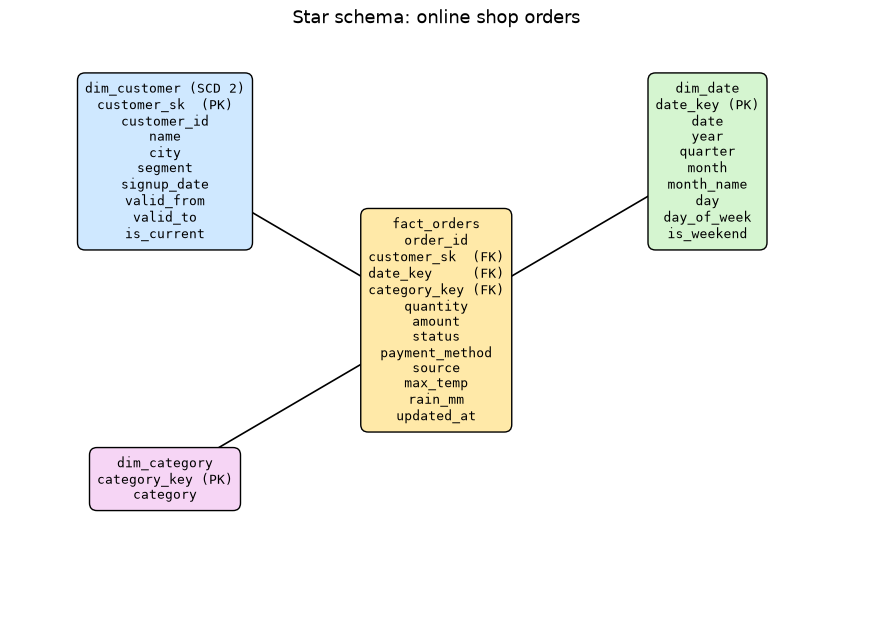

In [19]:
def box(ax, x, y, title, lines, color):
    text_block = title + "\n" + "\n".join(lines)
    ax.text(x, y, text_block, ha="center", va="center", fontsize=9, family="monospace",
            bbox=dict(boxstyle="round,pad=0.6", facecolor=color, edgecolor="black"))


fig, ax = plt.subplots(figsize=(11, 7.5))
ax.set_xlim(0, 11)
ax.set_ylim(0, 8)
ax.axis("off")

for x, y in [(2, 6.2), (9, 6.2), (2, 1.8)]:
    ax.plot([5.5, x], [4, y], color="black", linewidth=1.2)

box(ax, 5.5, 4, "fact_orders", ["order_id", "customer_sk  (FK)", "date_key     (FK)", "category_key (FK)", "quantity", "amount",
                                "status", "payment_method", "source", "max_temp", "rain_mm", "updated_at"], "#ffe9a8")
box(ax, 2, 6.2, "dim_customer (SCD 2)", ["customer_sk  (PK)", "customer_id", "name", "city", "segment", "signup_date",
                                         "valid_from", "valid_to", "is_current"], "#cfe8ff")
box(ax, 9, 6.2, "dim_date", ["date_key (PK)", "date", "year", "quarter", "month", "month_name", "day", "day_of_week", "is_weekend"], "#d5f5d0")
box(ax, 2, 1.8, "dim_category", ["category_key (PK)", "category"], "#f6d5f5")
ax.set_title("Star schema: online shop orders", fontsize=13)
plt.savefig("star_schema.png", dpi=150, bbox_inches="tight")
plt.show()

### 3.2 dim_date
One row per day from 2025-01-01 to 2026-12-31.

In [20]:
dates = pd.date_range("2025-01-01", "2026-12-31", freq="D")
dim_date = pd.DataFrame({
    "date_key": dates.strftime("%Y%m%d").astype(int),
    "date": dates.date,
    "year": dates.year,
    "quarter": dates.quarter,
    "month": dates.month,
    "month_name": dates.strftime("%B"),
    "day": dates.day,
    "day_of_week": dates.strftime("%A"),
    "is_weekend": dates.day_of_week >= 5,   # 5 = Saturday, 6 = Sunday
})
print(len(dim_date), "days")
dim_date.head(7)

730 days


,date_key,date,year,quarter,month,month_name,day,day_of_week,is_weekend
0,20250101,2025-01-01,2025,1,1,January,1,Wednesday,False
1,20250102,2025-01-02,2025,1,1,January,2,Thursday,False
2,20250103,2025-01-03,2025,1,1,January,3,Friday,False
3,20250104,2025-01-04,2025,1,1,January,4,Saturday,True
4,20250105,2025-01-05,2025,1,1,January,5,Sunday,True
5,20250106,2025-01-06,2025,1,1,January,6,Monday,False
6,20250107,2025-01-07,2025,1,1,January,7,Tuesday,False


### 3.3 dim_customer (SCD Type 2)
One row per customer per city.
- Customers who did not move: one row, valid from signup until `9999-12-31`.
- Customers who moved: an old-city row that ends the day before the move, and a current row starting on the move date.

I use Python dates here because a pandas timestamp cannot hold the year 9999.

In [21]:
FAR_FUTURE = date(9999, 12, 31)
moved = moves.set_index("customer_id")

rows = []
for c in customers.sort_values("customer_id").itertuples(index=False):
    base = {"customer_id": c.customer_id, "name": c.name, "segment": c.segment, "signup_date": c.signup_date.date()}
    if c.customer_id in moved.index:
        moved_on = moved.loc[c.customer_id, "moved_on"].date()
        rows.append({**base, "city": moved.loc[c.customer_id, "old_city"], "valid_from": c.signup_date.date(),
                     "valid_to": moved_on - timedelta(days=1), "is_current": False})
        rows.append({**base, "city": c.city, "valid_from": moved_on, "valid_to": FAR_FUTURE, "is_current": True})
    else:
        rows.append({**base, "city": c.city, "valid_from": c.signup_date.date(), "valid_to": FAR_FUTURE, "is_current": True})

dim_customer = pd.DataFrame(rows)
dim_customer.insert(0, "customer_sk", range(1, len(dim_customer) + 1))
dim_customer = dim_customer[["customer_sk", "customer_id", "name", "city", "segment", "signup_date", "valid_from", "valid_to", "is_current"]]

print(f"{len(dim_customer):,} rows for {dim_customer['customer_id'].nunique():,} customers ({len(moves)} moved)")
print("Customers without exactly one current row:", (dim_customer.groupby("customer_id")["is_current"].sum() != 1).sum())

2,057 rows for 2,000 customers (57 moved)
Customers without exactly one current row: 0


### 3.4 dim_category and fact_orders
An order must join to the customer row that was valid on the order date, so I join on `customer_id` and then keep the row where the date falls between `valid_from` and `valid_to`. If this is wrong, the orders of customers who moved get counted twice, so I check the row count.

In [22]:
dim_category = pd.DataFrame({"category": sorted(orders["category"].unique())})
dim_category.insert(0, "category_key", range(1, len(dim_category) + 1))

fact = orders.copy()
fact["order_day"] = fact["order_date"].dt.date
fact = fact.merge(dim_customer[["customer_sk", "customer_id", "city", "valid_from", "valid_to"]], on="customer_id")
fact = fact[(fact["order_day"] >= fact["valid_from"]) & (fact["order_day"] <= fact["valid_to"])]
assert len(fact) == len(orders)   # every order matches exactly one customer row
assert (fact["city"] == fact["order_city"]).all()   # same city that was used for the weather join

fact["date_key"] = fact["order_date"].dt.strftime("%Y%m%d").astype(int)
fact = fact.merge(dim_category, on="category")
assert fact["date_key"].isin(dim_date["date_key"]).all()

fact_orders = fact[["order_id", "customer_sk", "date_key", "category_key", "quantity", "amount", "status",
                    "payment_method", "source", "max_temp", "rain_mm", "updated_at"]] \
    .sort_values("order_id").reset_index(drop=True)
print(fact_orders.shape)
fact_orders.head()

(200000, 12)


,order_id,customer_sk,date_key,category_key,quantity,amount,status,payment_method,source,max_temp,rain_mm,updated_at
0,100001,268,20260901,3,1,77635.24,delivered,bank_transfer,web,NaN,NaN,2026-09-07 14:58:52
1,100002,102,20250228,5,1,5562.63,delivered,card,web,NaN,NaN,2025-03-05 07:26:15
2,100003,802,20260708,2,1,2055.15,shipped,card,web,NaN,NaN,2026-07-09 23:35:51
3,100004,1549,20250222,1,1,7414.43,delivered,wallet,web,21.9,0.0,2025-03-01 21:29:06
4,100005,165,20260112,2,4,6784.53,delivered,wallet,web,NaN,NaN,2026-01-14 02:59:49


### 3.5 Does the history match the app data?
The app documents record the real city at the time of each order, so they are a good test. For every app order that has a city, the `dim_customer` row picked by the date should show the same city.

In [23]:
test = app_seen.copy()
test["order_day"] = test["order_ts"].dt.date
test = test.merge(dim_customer[["customer_id", "city", "valid_from", "valid_to"]], on="customer_id")
test = test[(test["order_day"] >= test["valid_from"]) & (test["order_day"] <= test["valid_to"])]
print(f"App orders tested: {len(test):,}")
print(f"City matches dim_customer: {(test['app_city'] == test['city']).sum():,}")
print(f"Does not match: {(test['app_city'] != test['city']).sum()}")

App orders tested: 3,485
City matches dim_customer: 3,485
Does not match: 0


### 3.6 One customer who moved
I pick a customer who moved after February 2026, has an order in that month, and has an app order proving the new city.

In [24]:
later_moves = moves[(moves["moved_on"] > "2026-03-01") & (moves["evidence"] == "first order in new city")]
feb_orders = orders[(orders["customer_id"].isin(later_moves["customer_id"]))
                    & (orders["order_date"] >= "2026-02-01") & (orders["order_date"] < "2026-03-01")]
example_id = feb_orders["customer_id"].iloc[0]
example_order = feb_orders.iloc[0]

example_rows = dim_customer[dim_customer["customer_id"] == example_id]
print(example_rows.to_string(index=False))

used_sk = fact_orders.loc[fact_orders["order_id"] == example_order["order_id"], "customer_sk"].iloc[0]
used_row = dim_customer[dim_customer["customer_sk"] == used_sk].iloc[0]
print(f"\nOrder {example_order['order_id']} was placed on {example_order['order_date'].date()}.")
print(f"It joins to customer_sk {used_sk}, the {used_row['city']} row, because that date falls "
      f"between {used_row['valid_from']} and {used_row['valid_to']}.")

 customer_sk  customer_id          name       city  segment signup_date valid_from   valid_to  is_current
         482          469 Maryam Abbasi Rawalpindi Consumer  2024-07-08 2024-07-08 2026-09-19       False
         483          469 Maryam Abbasi     Multan Consumer  2024-07-08 2026-09-20 9999-12-31        True

Order 101578 was placed on 2026-02-20.
It joins to customer_sk 482, the Rawalpindi row, because that date falls between 2024-07-08 and 2026-09-19.


**Which row does a February 2026 order join to?** The row that was valid in February 2026. For this customer that is the old-city row, so old reports still show the old city. An order placed after the move joins to the row where `is_current` is true.

**Limit:** I can only see a move if the customer has an app order that shows the old city. Web orders do not record a city, so a customer who moved and has no such app order keeps one row. Most move dates are also estimates, because the app data only shows the city on a small sample of each customer's orders.

# Export for Databricks

Part 4 simulates a second load, so I split the fact table in two:
- `fact_orders_initial`: orders last updated on or before 2026-10-20 (the first load, version 0)
- `fact_orders_incremental`: orders updated after 2026-10-20 (the second load)

Spark cannot read the nanosecond timestamps pandas writes by default, so I save timestamps in microseconds.

In [25]:
def save(df, name):
    df.to_parquet(f"clean/{name}.parquet", index=False, coerce_timestamps="us", allow_truncated_timestamps=True)
    print(f"{name:26} {len(df):>8,} rows")


split_time = pd.Timestamp("2026-10-20")
weather_out = weather.assign(date=weather["date"].dt.date)
orders_out = orders.assign(order_date=orders["order_date"].dt.date)

save(orders_out, "orders_clean")
save(weather_out, "weather_daily")
save(dim_date, "dim_date")
save(dim_customer, "dim_customer")
save(dim_category, "dim_category")
save(fact_orders[fact_orders["updated_at"] <= split_time], "fact_orders_initial")
save(fact_orders[fact_orders["updated_at"] > split_time], "fact_orders_incremental")

quality.to_csv("clean/data_quality_results.csv", index=False)

orders_clean                200,000 rows
weather_daily                 1,986 rows
dim_date                        730 rows
dim_customer                  2,057 rows
dim_category                      6 rows
fact_orders_initial         197,153 rows


fact_orders_incremental       2,847 rows


In [26]:
# In Colab, this downloads the clean files so I can upload them to Databricks
try:
    from google.colab import files
    import shutil
    shutil.make_archive("clean_files", "zip", "clean")
    files.download("clean_files.zip")
except ImportError:
    print("Not in Colab: the files are in the clean/ folder")

Not in Colab: the files are in the clean/ folder
